# Voice Deepfake Detection - Training Pipeline

This notebook trains a MobileNetV2-based model to detect spoofed audio using 1-second spectrogram windows.

**Dataset:** LA (Logical Access) and PA (Physical Access) from ASVspoof 2019
- **LA**: Spoofed voices via synthesis/voice conversion
- **PA**: Playback attacks (replaying voice recordings)

**Strategy:** Use only readable FLAC files, split them into 1-second windows, and balance spoof vs bonafide windows within each corpus before training.

In [1]:
print("test")

test


In [4]:
import os
import sys
import math
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm


In [5]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

try:
    import tensorboard
    print(f"TensorBoard version: {tensorboard.__version__}")
except Exception as exc:
    print(f"TensorBoard import check failed: {exc}")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow version: 2.21.0
GPU Available: []
TensorBoard version: 2.20.0


In [6]:
# Paths
FLAC_LA_DIR = Path("../data/flac_sample/LA")
FLAC_PA_DIR = Path("../data/flac_sample/PA")
LA_LABELS_CSV = Path("../data/flac_sample/LA_sample_labels.csv")
PA_LABELS_CSV = Path("../data/flac_sample/PA_sample_labels.csv")
MODEL_SAVE_PATH = "models/voice_detector_model.h5"
PLOT_DIR = Path("plots")
TRAIN_DATA_DIR = Path("train_data")
TEST_DATA_DIR = Path("test_data")
PLOT_DIR.mkdir(exist_ok=True)
TRAIN_DATA_DIR.mkdir(exist_ok=True)
TEST_DATA_DIR.mkdir(exist_ok=True)

## Step 1: Load & Explore Data

In [7]:
# Load labels for LA and PA corpora
la_labels = pd.read_csv(LA_LABELS_CSV)
pa_labels = pd.read_csv(PA_LABELS_CSV)

# Add corpus column for distinction
la_labels['corpus'] = 'LA'
pa_labels['corpus'] = 'PA'

# Combine and shuffle
all_labels = pd.concat([la_labels, pa_labels], ignore_index=True)
all_labels = all_labels.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset Overview:")
print(f"Total samples: {len(all_labels)}")
print(f"\nLA corpus: {len(la_labels)} samples")
print(f"  - Bonafide (0): {(la_labels['label'] == 0).sum()}")
print(f"  - Spoof (1): {(la_labels['label'] == 1).sum()}")
print(f"\nPA corpus: {len(pa_labels)} samples")
print(f"  - Bonafide (0): {(pa_labels['label'] == 0).sum()}")
print(f"  - Spoof (1): {(pa_labels['label'] == 1).sum()}")
print(f"\nCombined (shuffled):")
print(f"  - Bonafide (0): {(all_labels['label'] == 0).sum()}")
print(f"  - Spoof (1): {(all_labels['label'] == 1).sum()}")
print(f"\nLabel distribution:\n{all_labels['label'].value_counts()}")
print(f"\nFirst 5 rows:\n{all_labels.head()}")

Dataset Overview:
Total samples: 8000

LA corpus: 4000 samples
  - Bonafide (0): 2000
  - Spoof (1): 2000

PA corpus: 4000 samples
  - Bonafide (0): 2000
  - Spoof (1): 2000

Combined (shuffled):
  - Bonafide (0): 4000
  - Spoof (1): 4000

Label distribution:
label
1    4000
0    4000
Name: count, dtype: int64

First 5 rows:
             id  label corpus
0  LA_E_9037359      1     LA
1  LA_E_5076224      0     LA
2  LA_E_7934220      0     LA
3  LA_E_3534768      1     LA
4  PA_E_1784580      1     PA


In [8]:
# Check file availability and audio integrity, then keep only valid files
print("Checking FLAC files...")
missing_files = []
unreadable_files = []
audio_stats = []
valid_indices = []

for idx, row in all_labels.iterrows():
    corpus = row['corpus']
    file_id = row['id']
    base_dir = FLAC_LA_DIR if corpus == 'LA' else FLAC_PA_DIR
    audio_path = base_dir / f"{file_id}.flac"
    
    if not audio_path.exists():
        missing_files.append((corpus, file_id, audio_path))
        continue

    try:
        data, sr = sf.read(str(audio_path), dtype='float32')
        audio_stats.append({
            'corpus': corpus,
            'id': file_id,
            'audio_path': str(audio_path),
            'sample_rate': sr,
            'duration_sec': len(data) / sr if sr > 0 else 0.0,
            'samples': len(data)
        })
        valid_indices.append(idx)
    except Exception as e:
        unreadable_files.append((corpus, file_id, audio_path, str(e)))

if missing_files:
    print(f"⚠️ Missing files: {len(missing_files)}")
    for corpus, fid, path in missing_files[:5]:
        print(f"  - {corpus}/{fid}: {path}")

if unreadable_files:
    print(f"⚠️ Unreadable FLAC files: {len(unreadable_files)}")
    for corpus, fid, path, err in unreadable_files[:10]:
        print(f"  - {corpus}/{fid}: {err}")

removed_count = len(all_labels) - len(valid_indices)
if removed_count > 0:
    all_labels = all_labels.loc[valid_indices].reset_index(drop=True)
    print(f"\nFiltered out {removed_count} invalid samples.")
else:
    print("✅ All audio files are readable!")

if audio_stats:
    print(f"\nAudio Statistics (from {len(audio_stats)} valid samples):")
    stats_df = pd.DataFrame(audio_stats)
    print(stats_df.groupby('corpus')[['sample_rate', 'duration_sec']].describe())
    all_labels['audio_path'] = all_labels.apply(
        lambda row: str((FLAC_LA_DIR if row['corpus'] == 'LA' else FLAC_PA_DIR) / f"{row['id']}.flac"),
        axis=1
    )
else:
    print("\nNo valid audio found after integrity check.")

Checking FLAC files...
⚠️ Unreadable FLAC files: 1746
  - LA/LA_E_9037359: Error : unknown error in flac decoder.
  - LA/LA_E_7934220: Error : flac decoder lost sync.
  - LA/LA_E_2485206: Error : unknown error in flac decoder.
  - LA/LA_E_3962205: Internal psf_fseek() failed.
  - LA/LA_E_5612408: Internal psf_fseek() failed.
  - LA/LA_E_1736309: Error : unknown error in flac decoder.
  - LA/LA_E_8774813: Error : unknown error in flac decoder.
  - LA/LA_E_6003996: Error : unknown error in flac decoder.
  - LA/LA_E_8458226: Internal psf_fseek() failed.
  - LA/LA_E_8823801: Error : unknown error in flac decoder.

Filtered out 1746 invalid samples.

Audio Statistics (from 6254 valid samples):
       sample_rate                                                             \
             count     mean  std      min      25%      50%      75%      max   
corpus                                                                          
LA          2254.0  16000.0  0.0  16000.0  16000.0  16000.0

## Step 2: Build 1-Second Window Metadata and Spectrograms

In [9]:
WINDOW_SEC = 1.0
TARGET_SAMPLE_RATE = 16000
TARGET_IMAGE_SIZE = (224, 224)
WINDOW_SAMPLE_FRAC = 0.25  # Use 25% windows to make training roughly 4x faster

import importlib
import subprocess
import tempfile

def _resolve_audioprocessor_dir() -> Path:
    """Locate the Rust crate directory regardless of notebook working directory."""
    candidates = [
        Path.cwd() / "audioprocessor",
        Path.cwd().parent / "audioprocessor",
        Path("../audioprocessor").resolve(),
    ]
    for candidate in candidates:
        if (candidate / "Cargo.toml").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find audioprocessor/Cargo.toml from the current notebook working directory."
    )

AUDIOPROCESSOR_DIR = _resolve_audioprocessor_dir()

def _build_and_install_rust_module(crate_dir: Path):
    """Build wheel with maturin and install it with pip (works without active virtualenv)."""
    wheel_out_dir = Path(tempfile.mkdtemp(prefix="audioprocessor_wheels_"))

    build_result = subprocess.run(
        [
            sys.executable,
            "-m",
            "maturin",
            "build",
            "--features",
            "python",
            "--interpreter",
            sys.executable,
            "--out",
            str(wheel_out_dir),
        ],
        cwd=str(crate_dir),
        check=False,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    if build_result.returncode != 0:
        raise RuntimeError(
            "maturin build failed.\n"
            f"stdout:\n{build_result.stdout}\n"
            f"stderr:\n{build_result.stderr}"
        )

    wheels = sorted(wheel_out_dir.glob("audioprocessor-*.whl"))
    if not wheels:
        raise RuntimeError(
            f"No wheel file was produced in {wheel_out_dir}.\n"
            f"maturin stdout:\n{build_result.stdout}\n"
            f"maturin stderr:\n{build_result.stderr}"
        )

    install_result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--force-reinstall", str(wheels[-1])],
        check=False,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    if install_result.returncode != 0:
        raise RuntimeError(
            "pip install of audioprocessor wheel failed.\n"
            f"stdout:\n{install_result.stdout}\n"
            f"stderr:\n{install_result.stderr}"
        )


def _ensure_rust_module():
    """Import audioprocessor module, and auto-build/install it when missing."""
    try:
        return importlib.import_module("audioprocessor")
    except ImportError:
        print(f"audioprocessor module not found. Building wheel with maturin in {AUDIOPROCESSOR_DIR}...")
        _build_and_install_rust_module(AUDIOPROCESSOR_DIR)
        importlib.invalidate_caches()
        return importlib.import_module("audioprocessor")

audioprocessor = _ensure_rust_module()

lfcc_converter = audioprocessor.LfccSpectrogramConverter(
    sample_rate=TARGET_SAMPLE_RATE,
    pre_emphasis_alpha=0.97,
    frame_length_ms=25.0,
    frame_step_ms=10.0,
    num_linear_filters=40,
    num_cepstral_coeffs=20,
    fft_size=512,
)

def build_window_metadata(files_df, window_sec=WINDOW_SEC, sample_rate=TARGET_SAMPLE_RATE, include_partial_last=True):
    """Build one-second window metadata for each readable FLAC file."""
    window_rows = []
    
    for _, row in tqdm(files_df.iterrows(), total=len(files_df), desc='Building windows'):
        audio_path = Path(row['audio_path'])
        corpus = row['corpus']
        file_id = row['id']
        label = int(row['label'])
        info = sf.info(str(audio_path))
        file_sample_rate = info.samplerate
        total_frames = info.frames

        file_samples_per_window = int(round(window_sec * file_sample_rate))
        
        if include_partial_last:
            total_windows = math.ceil(total_frames / file_samples_per_window)
        else:
            total_windows = total_frames // file_samples_per_window
        
        for window_index in range(total_windows):
            start_sample = window_index * file_samples_per_window
            if start_sample >= total_frames:
                continue
            end_sample = min(start_sample + file_samples_per_window, total_frames)
            window_rows.append({
                'window_id': f"{corpus}_{file_id}_w{window_index:04d}",
                'corpus': corpus,
                'file_id': file_id,
                'label': label,
                'audio_path': str(audio_path),
                'sample_rate': file_sample_rate,
                'window_sec': window_sec,
                'window_index': window_index,
                'window_start_sample': start_sample,
                'window_end_sample': end_sample,
                'window_frames': end_sample - start_sample
            })
    
    return pd.DataFrame(window_rows)

def audio_to_spectrogram(audio, sample_rate, target_size=TARGET_IMAGE_SIZE):
    """Convert a 1-second waveform window into normalized HWC image using Rust LFCC converter."""
    if audio.ndim > 1:
        audio = np.mean(audio, axis=1)

    if len(audio) == 0:
        audio = np.zeros(sample_rate, dtype=np.float32)

    if sample_rate != TARGET_SAMPLE_RATE:
        raise ValueError(f"Expected sample_rate={TARGET_SAMPLE_RATE}, got {sample_rate}.")

    rust_out = lfcc_converter.convert_window(audio.astype(np.float32).tolist())
    spec = np.array(rust_out, dtype=np.float32).reshape(3, target_size[0], target_size[1])
    spec = np.transpose(spec, (1, 2, 0))  # CHW -> HWC
    spec = spec - spec.min()
    spec = spec / (spec.max() - spec.min() + 1e-8)
    return spec.astype(np.float32)

print("Building 1-second window metadata from readable FLAC files...")
window_df = build_window_metadata(all_labels, window_sec=WINDOW_SEC, sample_rate=TARGET_SAMPLE_RATE, include_partial_last=True)

# Keep only a quarter of windows to speed up end-to-end training
if 0 < WINDOW_SAMPLE_FRAC < 1.0:
    prev_len = len(window_df)
    window_df = window_df.sample(frac=WINDOW_SAMPLE_FRAC, random_state=42).reset_index(drop=True)
    print(f"Window sampling enabled: kept {len(window_df)} of {prev_len} windows ({WINDOW_SAMPLE_FRAC:.0%}).")

print(f"Total windows after sampling: {len(window_df)}")
print(f"\nWindow label distribution:\n{window_df.groupby(['corpus', 'label']).size()}")
print(f"\nFirst 5 windows:\n{window_df.head()}")


Building 1-second window metadata from readable FLAC files...


Building windows: 100%|██████████| 6254/6254 [00:01<00:00, 3369.01it/s]

Window sampling enabled: kept 4709 of 18836 windows (25%).
Total windows after sampling: 4709

Window label distribution:
corpus  label
LA      0        1042
        1         873
PA      0        1410
        1        1384
dtype: int64

First 5 windows:
               window_id corpus       file_id  label  \
0  PA_PA_E_1656136_w0001     PA  PA_E_1656136      0   
1  PA_PA_E_1175858_w0000     PA  PA_E_1175858      1   
2  PA_PA_E_1070592_w0001     PA  PA_E_1070592      0   
3  LA_LA_E_3276055_w0000     LA  LA_E_3276055      1   
4  LA_LA_E_4250422_w0003     LA  LA_E_4250422      0   

                                 audio_path  sample_rate  window_sec  \
0  ..\data\flac_sample\PA\PA_E_1656136.flac        16000         1.0   
1  ..\data\flac_sample\PA\PA_E_1175858.flac        16000         1.0   
2  ..\data\flac_sample\PA\PA_E_1070592.flac        16000         1.0   
3  ..\data\flac_sample\LA\LA_E_3276055.flac        16000         1.0   
4  ..\data\flac_sample\LA\LA_E_4250422.flac     

## Step 3: Load 1-Second Window Spectrograms & Visualize

Loading sample 1-second window spectrograms...


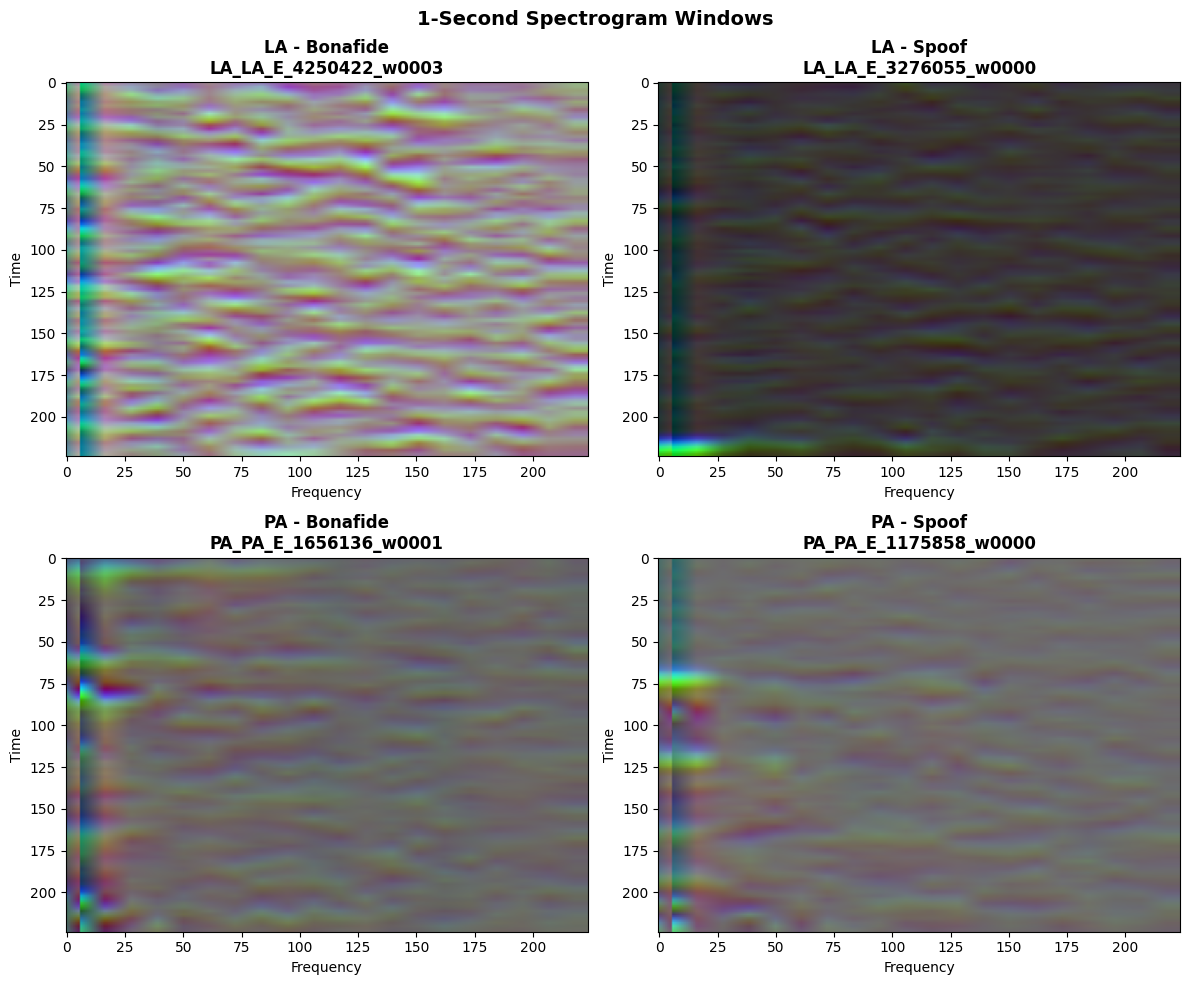

✅ Sample window spectrograms saved to plots/


In [10]:
def load_window_spectrogram(window_row):
    """Load a 1-second audio window and convert it into a spectrogram image."""
    try:
        audio_path = window_row['audio_path']
        start_sample = int(window_row['window_start_sample'])
        window_frames = int(window_row['window_frames'])
        sample_rate = int(window_row['sample_rate'])
        
        audio, sr = sf.read(
            str(audio_path),
            start=start_sample,
            frames=window_frames,
            dtype='float32',
            always_2d=False
        )
        
        if sr != sample_rate:
            sample_rate = sr
        
        if len(audio) < int(sample_rate * WINDOW_SEC):
            pad_len = int(sample_rate * WINDOW_SEC) - len(audio)
            if audio.ndim == 1:
                audio = np.pad(audio, (0, pad_len))
            else:
                audio = np.pad(audio, ((0, pad_len), (0, 0)))
        
        spec = audio_to_spectrogram(audio, sample_rate, target_size=TARGET_IMAGE_SIZE)
        return spec
    except Exception as e:
        print(f"Error loading window {window_row['window_id']}: {e}")
        return None

print("Loading sample 1-second window spectrograms...")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('1-Second Spectrogram Windows', fontsize=14, fontweight='bold')

samples_to_viz = [
    (window_df[(window_df['corpus'] == 'LA') & (window_df['label'] == 0)].iloc[0], 'LA - Bonafide', (0, 0)),
    (window_df[(window_df['corpus'] == 'LA') & (window_df['label'] == 1)].iloc[0], 'LA - Spoof', (0, 1)),
    (window_df[(window_df['corpus'] == 'PA') & (window_df['label'] == 0)].iloc[0], 'PA - Bonafide', (1, 0)),
    (window_df[(window_df['corpus'] == 'PA') & (window_df['label'] == 1)].iloc[0], 'PA - Spoof', (1, 1)),
]

for row, title, ax_pos in samples_to_viz:
    spec = load_window_spectrogram(row)
    if spec is not None:
        axes[ax_pos].imshow(spec, cmap='viridis', aspect='auto')
    else:
        axes[ax_pos].text(0.5, 0.5, 'Error loading', ha='center', va='center')
    axes[ax_pos].set_title(f"{title}\n{row['window_id']}", fontweight='bold')
    axes[ax_pos].set_xlabel('Frequency')
    axes[ax_pos].set_ylabel('Time')

plt.tight_layout()
plt.savefig(PLOT_DIR / 'sample_window_spectrograms.png', dpi=100, bbox_inches='tight')
plt.show()
print("✅ Sample window spectrograms saved to plots/")

## Step 4: Build Balanced Window Data Pipeline (Train/Val/Test Split)

In [11]:
def balance_window_df(data_df, label_col='label', random_state=42):
    """Downsample the majority class so spoof and bonafide windows are balanced."""
    class_counts = data_df[label_col].value_counts()
    if len(class_counts) < 2:
        return data_df.sample(frac=1, random_state=random_state).reset_index(drop=True)
    
    target_count = class_counts.min()
    balanced_parts = []
    for label_value in sorted(class_counts.index.tolist()):
        subset = data_df[data_df[label_col] == label_value]
        balanced_parts.append(subset.sample(n=target_count, random_state=random_state))
    
    balanced_df = pd.concat(balanced_parts, ignore_index=True)
    return balanced_df.sample(frac=1, random_state=random_state).reset_index(drop=True)

def split_files_and_windows(file_df, corpus_name, all_windows_df, random_state=42):
    """Split at file level first, then build balanced window splits."""
    train_files, temp_files = train_test_split(
        file_df, test_size=0.3, random_state=random_state, stratify=file_df['label']
    )
    val_files, test_files = train_test_split(
        temp_files, test_size=0.5, random_state=random_state, stratify=temp_files['label']
    )

    train_windows = all_windows_df[all_windows_df['file_id'].isin(train_files['id'])].copy()
    val_windows = all_windows_df[all_windows_df['file_id'].isin(val_files['id'])].copy()
    test_windows = all_windows_df[all_windows_df['file_id'].isin(test_files['id'])].copy()

    train_windows = balance_window_df(train_windows, random_state=random_state)
    val_windows = balance_window_df(val_windows, random_state=random_state)
    test_windows = balance_window_df(test_windows, random_state=random_state)

    print(f"{corpus_name} Dataset Split (balanced windows):")
    print(f"  Files - Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")
    print(f"  Windows - Train: {len(train_windows)} | Val: {len(val_windows)} | Test: {len(test_windows)}")
    print(f"  Train label counts:\n{train_windows['label'].value_counts().sort_index()}")
    print(f"  Val label counts:\n{val_windows['label'].value_counts().sort_index()}")
    print(f"  Test label counts:\n{test_windows['label'].value_counts().sort_index()}")

    return train_windows, val_windows, test_windows

la_file_data = all_labels[all_labels['corpus'] == 'LA'].reset_index(drop=True)
pa_file_data = all_labels[all_labels['corpus'] == 'PA'].reset_index(drop=True)

la_windows = window_df[window_df['corpus'] == 'LA'].reset_index(drop=True)
pa_windows = window_df[window_df['corpus'] == 'PA'].reset_index(drop=True)

la_train, la_val, la_test = split_files_and_windows(la_file_data, 'LA', la_windows)
pa_train, pa_val, pa_test = split_files_and_windows(pa_file_data, 'PA', pa_windows)

# Combined test set for ensemble evaluation (balanced per corpus, then combined)
combined_test = pd.concat([la_test, pa_test], ignore_index=True)
print(f"\nCombined Test Set: {len(combined_test)} windows (LA: {len(la_test)}, PA: {len(pa_test)})")

# Save dataset splits into separate folders for leakage validation
train_data_df = pd.concat([la_train, pa_train, la_val, pa_val], ignore_index=True)
test_data_df = combined_test.copy()

TRAIN_DATA_DIR.mkdir(exist_ok=True)
TEST_DATA_DIR.mkdir(exist_ok=True)

train_manifest_path = TRAIN_DATA_DIR / 'train_windows.csv'
test_manifest_path = TEST_DATA_DIR / 'test_windows.csv'
train_data_df.to_csv(train_manifest_path, index=False)
test_data_df.to_csv(test_manifest_path, index=False)

# Save supporting split manifests
la_train.to_csv(TRAIN_DATA_DIR / 'la_train_windows.csv', index=False)
la_val.to_csv(TRAIN_DATA_DIR / 'la_val_windows.csv', index=False)
pa_train.to_csv(TRAIN_DATA_DIR / 'pa_train_windows.csv', index=False)
pa_val.to_csv(TRAIN_DATA_DIR / 'pa_val_windows.csv', index=False)
la_test.to_csv(TEST_DATA_DIR / 'la_test_windows.csv', index=False)
pa_test.to_csv(TEST_DATA_DIR / 'pa_test_windows.csv', index=False)

# Leakage check at file_id level
train_file_ids = set(train_data_df['file_id'].unique().tolist())
test_file_ids = set(test_data_df['file_id'].unique().tolist())
leak_files = train_file_ids.intersection(test_file_ids)
print(f"Saved train manifest: {train_manifest_path}")
print(f"Saved test manifest: {test_manifest_path}")
print(f"Leakage check (file_id overlap): {len(leak_files)}")
if leak_files:
    print(f"Example leaked ids: {list(sorted(leak_files))[:10]}")
else:
    print("No file_id leakage detected between train_data and test_data.")


LA Dataset Split (balanced windows):
  Files - Train: 1577 | Val: 338 | Test: 339
  Windows - Train: 1246 | Val: 252 | Test: 248
  Train label counts:
label
0    623
1    623
Name: count, dtype: int64
  Val label counts:
label
0    126
1    126
Name: count, dtype: int64
  Test label counts:
label
0    124
1    124
Name: count, dtype: int64
PA Dataset Split (balanced windows):
  Files - Train: 2800 | Val: 600 | Test: 600
  Windows - Train: 1912 | Val: 396 | Test: 390
  Train label counts:
label
0    956
1    956
Name: count, dtype: int64
  Val label counts:
label
0    198
1    198
Name: count, dtype: int64
  Test label counts:
label
0    195
1    195
Name: count, dtype: int64

Combined Test Set: 638 windows (LA: 248, PA: 390)
Saved train manifest: train_data\train_windows.csv
Saved test manifest: test_data\test_windows.csv
Leakage check (file_id overlap): 0
No file_id leakage detected between train_data and test_data.


In [12]:
def data_generator(data_df, batch_size=32, augment=False, shuffle=True):
    """
    TensorFlow data generator that loads 1-second audio windows and converts them to spectrogram images.
    
    Args:
        data_df: DataFrame with window metadata
        batch_size: Batch size
        augment: Enable data augmentation
        shuffle: Shuffle data
    """
    if shuffle:
        data_df = data_df.sample(frac=1, random_state=None).reset_index(drop=True)
    
    def get_image_label(idx):
        row = data_df.iloc[idx]
        label = int(row['label'])
        
        try:
            audio, sr = sf.read(
                str(row['audio_path']),
                start=int(row['window_start_sample']),
                frames=int(row['window_frames']),
                dtype='float32',
                always_2d=False
            )
            
            target_length = int(sr * WINDOW_SEC)
            if len(audio) < target_length:
                pad_len = target_length - len(audio)
                if audio.ndim == 1:
                    audio = np.pad(audio, (0, pad_len))
                else:
                    audio = np.pad(audio, ((0, pad_len), (0, 0)))
            
            spec = audio_to_spectrogram(audio, sr, target_size=TARGET_IMAGE_SIZE)
        except Exception as e:
            print(f"Error loading {row['window_id']}: {e}")
            spec = np.zeros((TARGET_IMAGE_SIZE[0], TARGET_IMAGE_SIZE[1], 3), dtype=np.float32)
        
        if augment:
            if np.random.rand() > 0.5:
                spec = np.fliplr(spec)
            if np.random.rand() > 0.5:
                spec = np.flipud(spec)
            spec = spec * np.random.uniform(0.9, 1.1)
            spec = np.clip(spec, 0, 1)
        
        return spec.astype(np.float32), np.float32(label)
    
    def generator():
        for idx in range(len(data_df)):
            spec, label = get_image_label(idx)
            yield spec, label
    
    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(TARGET_IMAGE_SIZE[0], TARGET_IMAGE_SIZE[1], 3), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.float32)
        )
    )
    
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# Create datasets for LA (Model 1)
print("Creating LA data pipelines...")
BATCH_SIZE = 32

la_train_dataset = data_generator(la_train, batch_size=BATCH_SIZE, augment=True, shuffle=True)
la_val_dataset = data_generator(la_val, batch_size=BATCH_SIZE, augment=False, shuffle=False)
la_test_dataset = data_generator(la_test, batch_size=BATCH_SIZE, augment=False, shuffle=False)

# Create datasets for PA (Model 2)
print("Creating PA data pipelines...")
pa_train_dataset = data_generator(pa_train, batch_size=BATCH_SIZE, augment=True, shuffle=True)
pa_val_dataset = data_generator(pa_val, batch_size=BATCH_SIZE, augment=False, shuffle=False)
pa_test_dataset = data_generator(pa_test, batch_size=BATCH_SIZE, augment=False, shuffle=False)

print("✅ All datasets created successfully!")
print(f"\nLA Dataset:")
print(f"  Train: {len(la_train)} windows → {max(len(la_train)//BATCH_SIZE, 1)} batches")
print(f"  Val: {len(la_val)} windows → {max(len(la_val)//BATCH_SIZE, 1)} batches")
print(f"  Test: {len(la_test)} windows → {max(len(la_test)//BATCH_SIZE, 1)} batches")
print(f"\nPA Dataset:")
print(f"  Train: {len(pa_train)} windows → {max(len(pa_train)//BATCH_SIZE, 1)} batches")
print(f"  Val: {len(pa_val)} windows → {max(len(pa_val)//BATCH_SIZE, 1)} batches")
print(f"  Test: {len(pa_test)} windows → {max(len(pa_test)//BATCH_SIZE, 1)} batches")


Creating LA data pipelines...
Creating PA data pipelines...
✅ All datasets created successfully!

LA Dataset:
  Train: 1246 windows → 38 batches
  Val: 252 windows → 7 batches
  Test: 248 windows → 7 batches

PA Dataset:
  Train: 1912 windows → 59 batches
  Val: 396 windows → 12 batches
  Test: 390 windows → 12 batches


## Step 5: Build Model (MobileNetV2 Transfer Learning)

In [13]:
# Build 2 MobileNetV2 models: one for LA, one for PA
def build_detector_model(corpus_name='LA', input_shape=(224, 224, 3)):
    """
    Build MobileNetV2-based binary classifier for voice deepfake detection.
    
    Args:
        corpus_name: 'LA' or 'PA' - for specific training
        input_shape: Input image shape (224, 224, 3)
    
    Returns:
        Compiled Keras model
    """
    # Set random seed for reproducibility
    seed = 42
    tf.random.set_seed(seed)
    np.random.seed(seed)
    
    # Load pretrained MobileNetV2 (ImageNet weights)
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    
    # Freeze base model for transfer learning
    base_model.trainable = False
    
    # Build custom top layers
    inputs = tf.keras.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu', name='dense_256')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', name='dense_128')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=f'detector_{corpus_name}')
    
    # Compile with Adam optimizer
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )
    
    return model, base_model

# Build Model for LA
print("Building Model for LA (Logical Access)...")
model_la, base_model_la = build_detector_model(corpus_name='LA')

# Build Model for PA
print("Building Model for PA (Physical Access)...")
model_pa, base_model_pa = build_detector_model(corpus_name='PA')

print("\n" + "=" * 60)
print("LA Model Architecture:")
print("=" * 60)
model_la.summary()

print("\n" + "=" * 60)
print("PA Model Architecture:")
print("=" * 60)
model_pa.summary()

print(f"\nLA Model parameters: {model_la.count_params():,}")
print(f"PA Model parameters: {model_pa.count_params():,}")

Building Model for LA (Logical Access)...
Building Model for PA (Physical Access)...

LA Model Architecture:


Model: "detector_LA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,620,481 (10.00 MB)

 Trainable params: 361,729 (1.38 MB)

 Non-trainable params: 2,258,752 (8.62 MB)

... (3 outputs left out)

 Total params: 2,620,481 (10.00 MB)

 Trainable params: 361,729 (1.38 MB)

 Non-trainable params: 2,258,752 (8.62 MB)


LA Model parameters: 2,620,481
PA Model parameters: 2,620,481


## Step 6: Train Model

In [14]:
# Setup callbacks for both models
os.makedirs('models', exist_ok=True)

def create_callbacks(model_name, corpus):
    """Create training callbacks for a specific model."""
    model_checkpoint = f"models/voice_detector_{corpus}.h5"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=model_checkpoint,
            monitor='val_loss',
            save_best_only=True,
            mode='min',
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]

    try:
        import tensorboard  # noqa: F401
        callbacks.append(
            tf.keras.callbacks.TensorBoard(
                log_dir=f'./logs/detector_{corpus}',
                update_freq='epoch',
                histogram_freq=0
            )
        )
    except ImportError:
        print(f"TensorBoard is not available; skipping TensorBoard callback for {corpus}.")

    return callbacks

# Fewer epochs for faster turnaround (window count already reduced to 25%)
EPOCHS = 8

# Train LA Model
print("\n" + "=" * 60)
print("Training LA Model (Logical Access)...")
print("=" * 60)

callbacks_la = create_callbacks('LA Model', 'LA')
history_la = model_la.fit(
    la_train_dataset,
    validation_data=la_val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks_la,
    verbose=1
)

print("\n✅ LA Model training complete!")

# Train PA Model
print("\n" + "=" * 60)
print("Training PA Model (Physical Access)...")
print("=" * 60)

callbacks_pa = create_callbacks('PA Model', 'PA')
history_pa = model_pa.fit(
    pa_train_dataset,
    validation_data=pa_val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks_pa,
    verbose=1
)

print("\n✅ PA Model training complete!")


Training LA Model (Logical Access)...
Epoch 1/8
     39/Unknown 92s 2s/step - accuracy: 0.5348 - loss: 0.8656 - precision: 0.5408 - recall: 0.5563

c:\Users\Hi\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.67333, saving model to models/voice_detector_LA.h5



Epoch 1: finished saving model to models/voice_detector_LA.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 112s 3s/step - accuracy: 0.5522 - loss: 0.8151 - precision: 0.5501 - recall: 0.5730 - val_accuracy: 0.5675 - val_loss: 0.6733 - val_precision: 0.5739 - val_recall: 0.5238 - learning_rate: 1.0000e-04
Epoch 2/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6109 - loss: 0.7416 - precision: 0.6228 - recall: 0.5936
Epoch 2: val_loss improved from 0.67333 to 0.65923, saving model to models/voice_detector_LA.h5



Epoch 2: finished saving model to models/voice_detector_LA.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step - accuracy: 0.6083 - loss: 0.7382 - precision: 0.6080 - recall: 0.6100 - val_accuracy: 0.6071 - val_loss: 0.6592 - val_precision: 0.6116 - val_recall: 0.5873 - learning_rate: 1.0000e-04
Epoch 3/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6004 - loss: 0.7308 - precision: 0.6069 - recall: 0.6059
Epoch 3: val_loss did not improve from 0.65923
39/39 ━━━━━━━━━━━━━━━━━━━━ 99s 3s/step - accuracy: 0.6075 - loss: 0.7223 - precision: 0.6060 - recall: 0.6148 - val_accuracy: 0.6032 - val_loss: 0.6612 - val_precision: 0.5677 - val_recall: 0.8651 - learning_rate: 1.0000e-04
Epoch 4/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6307 - loss: 0.6802 - precision: 0.6334 - recall: 0.6493
Epoch 4: val_loss improved from 0.65923 to 0.64117, saving model to models/voice_detector_LA.h5



Epoch 4: finished saving model to models/voice_detector_LA.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.6324 - loss: 0.6830 - precision: 0.6279 - recall: 0.6501 - val_accuracy: 0.6071 - val_loss: 0.6412 - val_precision: 0.6015 - val_recall: 0.6349 - learning_rate: 1.0000e-04
Epoch 5/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6511 - loss: 0.6605 - precision: 0.6579 - recall: 0.6536
Epoch 5: val_loss did not improve from 0.64117
39/39 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step - accuracy: 0.6477 - loss: 0.6658 - precision: 0.6494 - recall: 0.6421 - val_accuracy: 0.5794 - val_loss: 0.6562 - val_precision: 0.5676 - val_recall: 0.6667 - learning_rate: 1.0000e-04
Epoch 6/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6457 - loss: 0.6419 - precision: 0.6551 - recall: 0.6412
Epoch 6: val_loss improved from 0.64117 to 0.63717, saving model to models/voice_detector_LA.h5



Epoch 6: finished saving model to models/voice_detector_LA.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 105s 3s/step - accuracy: 0.6461 - loss: 0.6581 - precision: 0.6413 - recall: 0.6629 - val_accuracy: 0.5913 - val_loss: 0.6372 - val_precision: 0.5714 - val_recall: 0.7302 - learning_rate: 1.0000e-04
Epoch 7/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6567 - loss: 0.6382 - precision: 0.6613 - recall: 0.6649
Epoch 7: val_loss did not improve from 0.63717
39/39 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 0.6621 - loss: 0.6344 - precision: 0.6593 - recall: 0.6709 - val_accuracy: 0.5794 - val_loss: 0.7484 - val_precision: 0.5495 - val_recall: 0.8810 - learning_rate: 1.0000e-04
Epoch 8/8
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6569 - loss: 0.6354 - precision: 0.6601 - recall: 0.6702
Epoch 8: val_loss did not improve from 0.63717
39/39 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 0.6677 - loss: 0.6319 - precision: 0.6605 - recall: 0.6902 - val_accuracy: 0.5873 - val_loss: 0.6967 


Epoch 1: finished saving model to models/voice_detector_PA.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 180s 3s/step - accuracy: 0.5340 - loss: 0.8211 - precision_1: 0.5340 - recall_1: 0.5335 - val_accuracy: 0.5985 - val_loss: 0.6692 - val_precision_1: 0.5670 - val_recall_1: 0.8333 - learning_rate: 1.0000e-04
Epoch 2/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5559 - loss: 0.7956 - precision_1: 0.5561 - recall_1: 0.5781
Epoch 2: val_loss improved from 0.66921 to 0.66271, saving model to models/voice_detector_PA.h5



Epoch 2: finished saving model to models/voice_detector_PA.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 167s 3s/step - accuracy: 0.5523 - loss: 0.7882 - precision_1: 0.5510 - recall_1: 0.5649 - val_accuracy: 0.5732 - val_loss: 0.6627 - val_precision_1: 0.5587 - val_recall_1: 0.6970 - learning_rate: 1.0000e-04
Epoch 3/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5535 - loss: 0.7831 - precision_1: 0.5571 - recall_1: 0.5496
Epoch 3: val_loss did not improve from 0.66271
60/60 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.5549 - loss: 0.7783 - precision_1: 0.5546 - recall_1: 0.5575 - val_accuracy: 0.5732 - val_loss: 0.6641 - val_precision_1: 0.6058 - val_recall_1: 0.4192 - learning_rate: 1.0000e-04
Epoch 4/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5478 - loss: 0.7741 - precision_1: 0.5529 - recall_1: 0.5285
Epoch 4: val_loss did not improve from 0.66271
60/60 ━━━━━━━━━━━━━━━━━━━━ 158s 3s/step - accuracy: 0.5445 - loss: 0.7737 - precision_1: 0.5456 - recall_1: 0.5324 - val_accuracy


Epoch 6: finished saving model to models/voice_detector_PA.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 173s 3s/step - accuracy: 0.5664 - loss: 0.7304 - precision_1: 0.5661 - recall_1: 0.5690 - val_accuracy: 0.6187 - val_loss: 0.6603 - val_precision_1: 0.6374 - val_recall_1: 0.5505 - learning_rate: 5.0000e-05
Epoch 7/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5611 - loss: 0.7414 - precision_1: 0.5642 - recall_1: 0.5640
Epoch 7: val_loss did not improve from 0.66035
60/60 ━━━━━━━━━━━━━━━━━━━━ 163s 3s/step - accuracy: 0.5785 - loss: 0.7322 - precision_1: 0.5798 - recall_1: 0.5701 - val_accuracy: 0.6061 - val_loss: 0.6617 - val_precision_1: 0.6265 - val_recall_1: 0.5253 - learning_rate: 5.0000e-05
Epoch 8/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5867 - loss: 0.7324 - precision_1: 0.5890 - recall_1: 0.5921
Epoch 8: val_loss did not improve from 0.66035
60/60 ━━━━━━━━━━━━━━━━━━━━ 209s 4s/step - accuracy: 0.5769 - loss: 0.7308 - precision_1: 0.5763 - recall_1: 0.5805 - val_accuracy

## Step 7: Visualize Training History

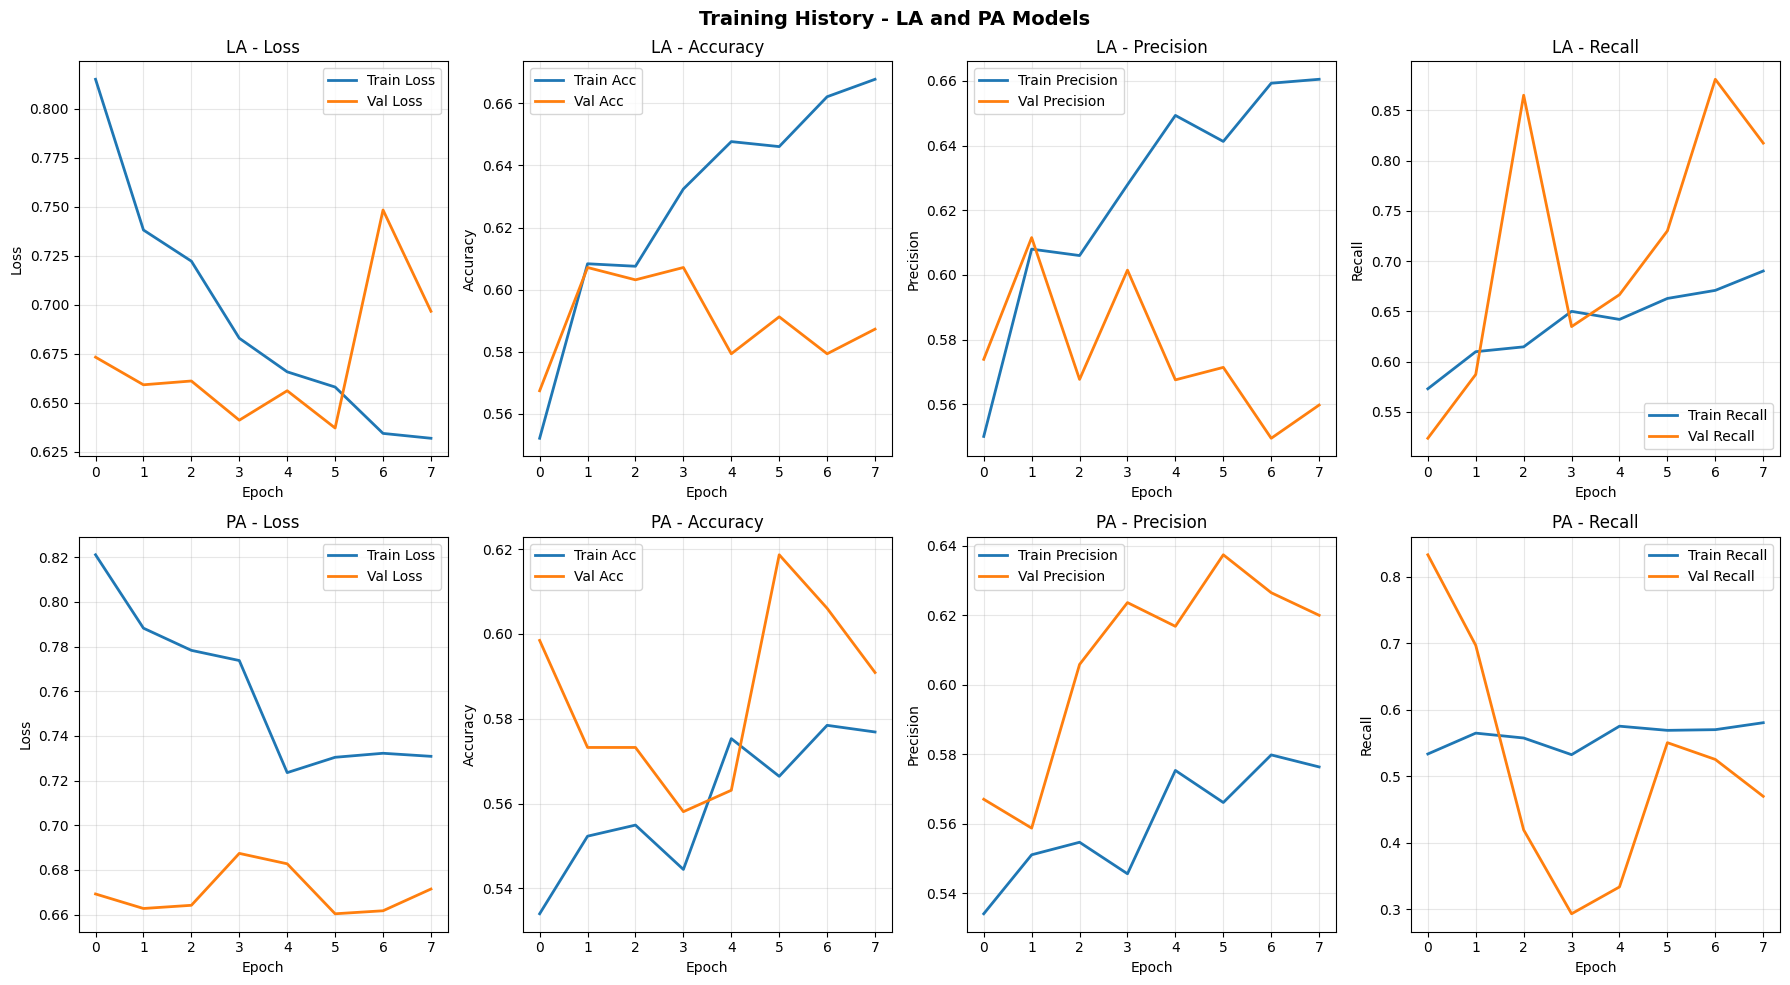

✅ Training history plots saved to plots/


In [17]:
# Plot training history for both models
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
fig.suptitle('Training History - LA and PA Models', fontsize=14, fontweight='bold')

def pick_metric_keys(history_dict, base_name):
    """Return train/val metric keys, handling suffixes like precision_1."""
    train_key = None
    for candidate in [base_name] + [k for k in history_dict.keys() if k.startswith(base_name + '_')]:
        if candidate in history_dict:
            train_key = candidate
            break

    val_key = None
    if train_key is not None:
        expected_val = f'val_{train_key}'
        if expected_val in history_dict:
            val_key = expected_val
        else:
            for candidate in [f'val_{base_name}'] + [k for k in history_dict.keys() if k.startswith(f'val_{base_name}_')]:
                if candidate in history_dict:
                    val_key = candidate
                    break
    return train_key, val_key

# LA Model History
# Loss
axes[0, 0].plot(history_la.history['loss'], label='Train Loss', linewidth=2)
axes[0, 0].plot(history_la.history['val_loss'], label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('LA - Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history_la.history['accuracy'], label='Train Acc', linewidth=2)
axes[0, 1].plot(history_la.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('LA - Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision
la_prec_k, la_val_prec_k = pick_metric_keys(history_la.history, 'precision')
if la_prec_k and la_val_prec_k:
    axes[0, 2].plot(history_la.history[la_prec_k], label='Train Precision', linewidth=2)
    axes[0, 2].plot(history_la.history[la_val_prec_k], label='Val Precision', linewidth=2)
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('Precision')
axes[0, 2].set_title('LA - Precision')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# Recall
la_rec_k, la_val_rec_k = pick_metric_keys(history_la.history, 'recall')
if la_rec_k and la_val_rec_k:
    axes[0, 3].plot(history_la.history[la_rec_k], label='Train Recall', linewidth=2)
    axes[0, 3].plot(history_la.history[la_val_rec_k], label='Val Recall', linewidth=2)
axes[0, 3].set_xlabel('Epoch')
axes[0, 3].set_ylabel('Recall')
axes[0, 3].set_title('LA - Recall')
axes[0, 3].legend()
axes[0, 3].grid(True, alpha=0.3)

# PA Model History
# Loss
axes[1, 0].plot(history_pa.history['loss'], label='Train Loss', linewidth=2)
axes[1, 0].plot(history_pa.history['val_loss'], label='Val Loss', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].set_title('PA - Loss')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Accuracy
axes[1, 1].plot(history_pa.history['accuracy'], label='Train Acc', linewidth=2)
axes[1, 1].plot(history_pa.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].set_title('PA - Accuracy')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Precision
pa_prec_k, pa_val_prec_k = pick_metric_keys(history_pa.history, 'precision')
if pa_prec_k and pa_val_prec_k:
    axes[1, 2].plot(history_pa.history[pa_prec_k], label='Train Precision', linewidth=2)
    axes[1, 2].plot(history_pa.history[pa_val_prec_k], label='Val Precision', linewidth=2)
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Precision')
axes[1, 2].set_title('PA - Precision')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

# Recall
pa_rec_k, pa_val_rec_k = pick_metric_keys(history_pa.history, 'recall')
if pa_rec_k and pa_val_rec_k:
    axes[1, 3].plot(history_pa.history[pa_rec_k], label='Train Recall', linewidth=2)
    axes[1, 3].plot(history_pa.history[pa_val_rec_k], label='Val Recall', linewidth=2)
axes[1, 3].set_xlabel('Epoch')
axes[1, 3].set_ylabel('Recall')
axes[1, 3].set_title('PA - Recall')
axes[1, 3].legend()
axes[1, 3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / 'training_history_both_models.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Training history plots saved to plots/")

## Step 8: Evaluate on Test Set

In [16]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
)

# Load best models
model_la_best = tf.keras.models.load_model('models/voice_detector_LA.h5')
model_pa_best = tf.keras.models.load_model('models/voice_detector_PA.h5')

print("=" * 60)
print("INDIVIDUAL MODEL EVALUATION")
print("=" * 60)

# Evaluate LA model on LA test set
print("\nLA Model on LA Test Set:")
la_loss, la_acc, la_prec, la_rec = model_la_best.evaluate(la_test_dataset, verbose=0)
print(f"  Loss: {la_loss:.4f} | Accuracy: {la_acc:.4f} | Precision: {la_prec:.4f} | Recall: {la_rec:.4f}")

# Evaluate PA model on PA test set
print("\nPA Model on PA Test Set:")
pa_loss, pa_acc, pa_prec, pa_rec = model_pa_best.evaluate(pa_test_dataset, verbose=0)
print(f"  Loss: {pa_loss:.4f} | Accuracy: {pa_acc:.4f} | Precision: {pa_prec:.4f} | Recall: {pa_rec:.4f}")

print("\n" + "=" * 60)
print("ENSEMBLE EVALUATION (on combined test set)")
print("=" * 60)

# Gather predictions from both models on combined test set
print("\nGathering ensemble predictions...")

all_predictions_la = []
all_predictions_pa = []
all_labels_ensemble = []
all_corpus_labels = []

# Predict on LA test set with both models
for spec_batch, label_batch in la_test_dataset:
    preds_la = model_la_best.predict(spec_batch, verbose=0)
    preds_pa = model_pa_best.predict(spec_batch, verbose=0)
    all_predictions_la.extend(preds_la.flatten())
    all_predictions_pa.extend(preds_pa.flatten())
    all_labels_ensemble.extend(label_batch.numpy())
    all_corpus_labels.extend(['LA'] * len(label_batch))

# Predict on PA test set with both models
for spec_batch, label_batch in pa_test_dataset:
    preds_la = model_la_best.predict(spec_batch, verbose=0)
    preds_pa = model_pa_best.predict(spec_batch, verbose=0)
    all_predictions_la.extend(preds_la.flatten())
    all_predictions_pa.extend(preds_pa.flatten())
    all_labels_ensemble.extend(label_batch.numpy())
    all_corpus_labels.extend(['PA'] * len(label_batch))

all_predictions_la = np.array(all_predictions_la)
all_predictions_pa = np.array(all_predictions_pa)
all_labels_ensemble = np.array(all_labels_ensemble)

# Ensemble: Average predictions from both models
ensemble_predictions = (all_predictions_la + all_predictions_pa) / 2.0
ensemble_binary = (ensemble_predictions > 0.5).astype(int)

# LA model only (on combined set)
la_model_binary = (all_predictions_la > 0.5).astype(int)

# PA model only (on combined set)
pa_model_binary = (all_predictions_pa > 0.5).astype(int)

print("\n📊 RESULTS SUMMARY:")
print("=" * 60)

# Calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_eer(y_true, y_score):
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    fnr = 1.0 - tpr
    idx = np.nanargmin(np.abs(fnr - fpr))
    eer = (fpr[idx] + fnr[idx]) / 2.0
    eer_threshold = thresholds[idx]
    return eer, eer_threshold, fpr, tpr

print("\nLA Model (on combined test):")
la_acc = accuracy_score(all_labels_ensemble, la_model_binary)
la_prec = precision_score(all_labels_ensemble, la_model_binary, zero_division=0)
la_rec = recall_score(all_labels_ensemble, la_model_binary, zero_division=0)
la_f1 = f1_score(all_labels_ensemble, la_model_binary, zero_division=0)
la_auc = roc_auc_score(all_labels_ensemble, all_predictions_la)
la_eer, la_eer_thr, fpr_la, tpr_la = compute_eer(all_labels_ensemble, all_predictions_la)
print(f"  Accuracy: {la_acc:.4f} | Precision: {la_prec:.4f} | Recall: {la_rec:.4f} | F1: {la_f1:.4f} | AUC: {la_auc:.4f} | EER: {la_eer:.4f}")

print("\nPA Model (on combined test):")
pa_acc = accuracy_score(all_labels_ensemble, pa_model_binary)
pa_prec = precision_score(all_labels_ensemble, pa_model_binary, zero_division=0)
pa_rec = recall_score(all_labels_ensemble, pa_model_binary, zero_division=0)
pa_f1 = f1_score(all_labels_ensemble, pa_model_binary, zero_division=0)
pa_auc = roc_auc_score(all_labels_ensemble, all_predictions_pa)
pa_eer, pa_eer_thr, fpr_pa, tpr_pa = compute_eer(all_labels_ensemble, all_predictions_pa)
print(f"  Accuracy: {pa_acc:.4f} | Precision: {pa_prec:.4f} | Recall: {pa_rec:.4f} | F1: {pa_f1:.4f} | AUC: {pa_auc:.4f} | EER: {pa_eer:.4f}")

print("\n🎯 ENSEMBLE (Average of LA + PA):")
ens_acc = accuracy_score(all_labels_ensemble, ensemble_binary)
ens_prec = precision_score(all_labels_ensemble, ensemble_binary, zero_division=0)
ens_rec = recall_score(all_labels_ensemble, ensemble_binary, zero_division=0)
ens_f1 = f1_score(all_labels_ensemble, ensemble_binary, zero_division=0)
ens_auc = roc_auc_score(all_labels_ensemble, ensemble_predictions)
ens_eer, ens_eer_thr, fpr_ens, tpr_ens = compute_eer(all_labels_ensemble, ensemble_predictions)
print(f"  Accuracy: {ens_acc:.4f} | Precision: {ens_prec:.4f} | Recall: {ens_rec:.4f} | F1: {ens_f1:.4f} | AUC: {ens_auc:.4f} | EER: {ens_eer:.4f}")

print("\nEER thresholds:")
print(f"  LA threshold @EER: {la_eer_thr:.4f}")
print(f"  PA threshold @EER: {pa_eer_thr:.4f}")
print(f"  Ensemble threshold @EER: {ens_eer_thr:.4f}")

print("\n" + "=" * 60)
print("Ensemble Classification Report:")
print(classification_report(all_labels_ensemble, ensemble_binary, target_names=['Bonafide', 'Spoof']))

# Confusion matrix for ensemble
cm_ensemble = confusion_matrix(all_labels_ensemble, ensemble_binary)
print(f"\nEnsemble Confusion Matrix:")
print(f"  TN: {cm_ensemble[0,0]}, FP: {cm_ensemble[0,1]}")
print(f"  FN: {cm_ensemble[1,0]}, TP: {cm_ensemble[1,1]}")

INDIVIDUAL MODEL EVALUATION

LA Model on LA Test Set:


c:\Users\Hi\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  Loss: 0.5632 | Accuracy: 0.7218 | Precision: 0.6846 | Recall: 0.8226

PA Model on PA Test Set:
  Loss: 0.7048 | Accuracy: 0.5513 | Precision: 0.5510 | Recall: 0.5538

ENSEMBLE EVALUATION (on combined test set)

Gathering ensemble predictions...

📊 RESULTS SUMMARY:

LA Model (on combined test):
  Accuracy: 0.5940 | Precision: 0.5955 | Recall: 0.5862 | F1: 0.5908 | AUC: 0.6278 | EER: 0.4013

PA Model (on combined test):
  Accuracy: 0.4906 | Precision: 0.4894 | Recall: 0.4326 | F1: 0.4592 | AUC: 0.4859 | EER: 0.5094

🎯 ENSEMBLE (Average of LA + PA):
  Accuracy: 0.5784 | Precision: 0.5893 | Recall: 0.5172 | F1: 0.5509 | AUC: 0.6124 | EER: 0.4122

EER thresholds:
  LA threshold @EER: 0.4957
  PA threshold @EER: 0.4689
  Ensemble threshold @EER: 0.4831

Ensemble Classification Report:
              precision    recall  f1-score   support

    Bonafide       0.57      0.64      0.60       319
       Spoof       0.59      0.52      0.55       319

    accuracy                           0.58 

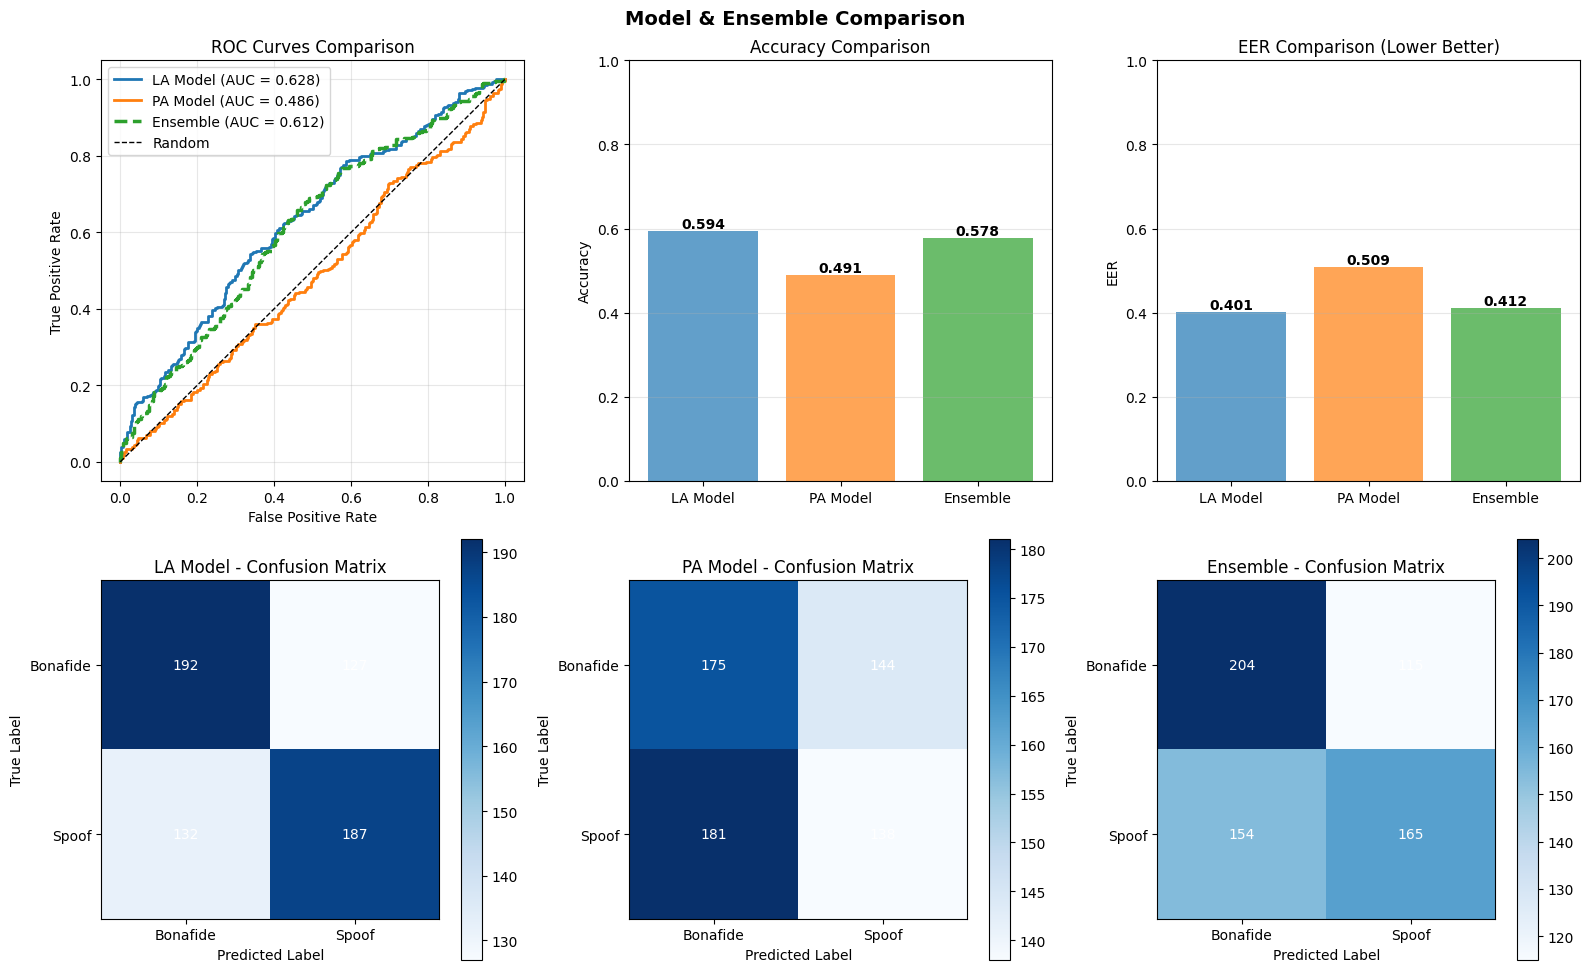

✅ Ensemble evaluation plots (including EER) saved to plots/


In [18]:
# Visualize evaluation metrics - Model comparison
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Model & Ensemble Comparison', fontsize=14, fontweight='bold')

# ROC Curves
if 'fpr_la' not in globals() or 'fpr_pa' not in globals() or 'fpr_ens' not in globals():
    fpr_la, tpr_la, _ = roc_curve(all_labels_ensemble, all_predictions_la)
    fpr_pa, tpr_pa, _ = roc_curve(all_labels_ensemble, all_predictions_pa)
    fpr_ens, tpr_ens, _ = roc_curve(all_labels_ensemble, ensemble_predictions)

axes[0, 0].plot(fpr_la, tpr_la, linewidth=2, label=f'LA Model (AUC = {la_auc:.3f})')
axes[0, 0].plot(fpr_pa, tpr_pa, linewidth=2, label=f'PA Model (AUC = {pa_auc:.3f})')
axes[0, 0].plot(fpr_ens, tpr_ens, linewidth=2.5, label=f'Ensemble (AUC = {ens_auc:.3f})', linestyle='--')
axes[0, 0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('ROC Curves Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy comparison
models = ['LA Model', 'PA Model', 'Ensemble']
accuracies = [la_acc, pa_acc, ens_acc]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
bars1 = axes[0, 1].bar(models, accuracies, color=colors, alpha=0.7)
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Accuracy Comparison')
axes[0, 1].set_ylim([0, 1])
axes[0, 1].grid(True, alpha=0.3, axis='y')
for bar, acc in zip(bars1, accuracies):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height,
                   f'{acc:.3f}', ha='center', va='bottom', fontweight='bold')

# EER comparison (lower is better)
eers = [la_eer, pa_eer, ens_eer]
bars2 = axes[0, 2].bar(models, eers, color=colors, alpha=0.7)
axes[0, 2].set_ylabel('EER')
axes[0, 2].set_title('EER Comparison (Lower Better)')
axes[0, 2].set_ylim([0, 1])
axes[0, 2].grid(True, alpha=0.3, axis='y')
for bar, eer in zip(bars2, eers):
    height = bar.get_height()
    axes[0, 2].text(bar.get_x() + bar.get_width()/2., height,
                   f'{eer:.3f}', ha='center', va='bottom', fontweight='bold')

# Confusion Matrices
cm_la = confusion_matrix(all_labels_ensemble, la_model_binary)
cm_pa = confusion_matrix(all_labels_ensemble, pa_model_binary)

# LA Confusion Matrix
im1 = axes[1, 0].imshow(cm_la, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 0].figure.colorbar(im1, ax=axes[1, 0])
axes[1, 0].set(xticks=np.arange(2), yticks=np.arange(2),
               xticklabels=['Bonafide', 'Spoof'],
               yticklabels=['Bonafide', 'Spoof'])
axes[1, 0].set_ylabel('True Label')
axes[1, 0].set_xlabel('Predicted Label')
axes[1, 0].set_title('LA Model - Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[1, 0].text(j, i, f'{cm_la[i, j]}', ha='center', va='center',
                       color='white' if cm_la[i, j] > cm_la.max() / 2 else 'black')

# PA Confusion Matrix
im2 = axes[1, 1].imshow(cm_pa, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 1].figure.colorbar(im2, ax=axes[1, 1])
axes[1, 1].set(xticks=np.arange(2), yticks=np.arange(2),
               xticklabels=['Bonafide', 'Spoof'],
               yticklabels=['Bonafide', 'Spoof'])
axes[1, 1].set_ylabel('True Label')
axes[1, 1].set_xlabel('Predicted Label')
axes[1, 1].set_title('PA Model - Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[1, 1].text(j, i, f'{cm_pa[i, j]}', ha='center', va='center',
                       color='white' if cm_pa[i, j] > cm_pa.max() / 2 else 'black')

# Ensemble Confusion Matrix
im3 = axes[1, 2].imshow(cm_ensemble, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 2].figure.colorbar(im3, ax=axes[1, 2])
axes[1, 2].set(xticks=np.arange(2), yticks=np.arange(2),
               xticklabels=['Bonafide', 'Spoof'],
               yticklabels=['Bonafide', 'Spoof'])
axes[1, 2].set_ylabel('True Label')
axes[1, 2].set_xlabel('Predicted Label')
axes[1, 2].set_title('Ensemble - Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[1, 2].text(j, i, f'{cm_ensemble[i, j]}', ha='center', va='center',
                       color='white' if cm_ensemble[i, j] > cm_ensemble.max() / 2 else 'black')

plt.tight_layout()
plt.savefig(PLOT_DIR / 'ensemble_evaluation_metrics.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Ensemble evaluation plots (including EER) saved to plots/")

## Step 9: Model Conversion & Summary

In [19]:
# Model information
print("\n" + "=" * 60)
print("ENSEMBLE MODEL SUMMARY")
print("=" * 60)

print("\n📦 Models Saved:")
print(f"  - LA Model: models/voice_detector_LA.h5")
print(f"    Size: {os.path.getsize('models/voice_detector_LA.h5') / 1024 / 1024:.2f} MB")
print(f"    Parameters: {model_la_best.count_params():,}")

print(f"\n  - PA Model: models/voice_detector_PA.h5")
print(f"    Size: {os.path.getsize('models/voice_detector_PA.h5') / 1024 / 1024:.2f} MB")
print(f"    Parameters: {model_pa_best.count_params():,}")

print(f"\nTotal Ensemble Size: {(os.path.getsize('models/voice_detector_LA.h5') + os.path.getsize('models/voice_detector_PA.h5')) / 1024 / 1024:.2f} MB")

print("\n🎯 Ensemble Strategy:")
print("  1. Input audio -> Rust converter -> LFCC spectrogram (224x224x3)")
print("  2. LA Model predicts: P_LA = model_la(spectrogram)")
print("  3. PA Model predicts: P_PA = model_pa(spectrogram)")
print("  4. Ensemble prediction: P_ensemble = (P_LA + P_PA) / 2")
print("  5. Final class: 0 (Bonafide) if P_ensemble < 0.5, else 1 (Spoof)")

print("\n📊 Best Performance:")
print(f"  LA Model Accuracy: {la_acc:.4f}")
print(f"  PA Model Accuracy: {pa_acc:.4f}")
print(f"  Ensemble Accuracy: {ens_acc:.4f}")
print(f"  Ensemble AUC: {ens_auc:.4f}")
print(f"  Ensemble EER: {ens_eer:.4f} ⭐")

# Convert both models to TFLite
print("\n🔄 Converting models to TensorFlow Lite (quantized)...")

for model, name in [(model_la_best, 'LA'), (model_pa_best, 'PA')]:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    
    tflite_path = f'models/voice_detector_{name}_quantized.tflite'
    with open(tflite_path, 'wb') as f:
        f.write(tflite_model)
    
    size_mb = os.path.getsize(tflite_path) / 1024 / 1024
    print(f"✅ {name} Model TFLite: {tflite_path} ({size_mb:.2f} MB)")

print("\n" + "=" * 60)
print("TRAINING COMPLETE!")
print("=" * 60)

print("\n📍 Next steps:")
print("1. Deploy both models to edge device (use TFLite versions)")
print("2. Integrate Rust converter for real-time audio feature extraction")
print("3. Implement ensemble inference pipeline")
print("4. Fine-tune on new data if domain shift detected")
print("5. Monitor ensemble performance across both corpora")
print("6. Consider expanding to additional attack types (ASVspoof 2021, 2022)")

print("\n💡 Deployment Tips:")
print("- LA model: Specialized for synthesis/voice conversion attacks")
print("- PA model: Specialized for replay/playback attacks")
print("- Use ensemble for robust cross-attack detection")
print("- Cache Rust converter output for batch processing")


ENSEMBLE MODEL SUMMARY

📦 Models Saved:
  - LA Model: models/voice_detector_LA.h5
    Size: 13.13 MB
    Parameters: 2,620,481

  - PA Model: models/voice_detector_PA.h5
    Size: 13.13 MB
    Parameters: 2,620,481

Total Ensemble Size: 26.27 MB

🎯 Ensemble Strategy:
  1. Input audio -> Rust converter -> LFCC spectrogram (224x224x3)
  2. LA Model predicts: P_LA = model_la(spectrogram)
  3. PA Model predicts: P_PA = model_pa(spectrogram)
  4. Ensemble prediction: P_ensemble = (P_LA + P_PA) / 2
  5. Final class: 0 (Bonafide) if P_ensemble < 0.5, else 1 (Spoof)

📊 Best Performance:
  LA Model Accuracy: 0.5940
  PA Model Accuracy: 0.4906
  Ensemble Accuracy: 0.5784
  Ensemble AUC: 0.6124
  Ensemble EER: 0.4122 ⭐

🔄 Converting models to TensorFlow Lite (quantized)...
INFO:tensorflow:Assets written to: C:\Users\Hi\AppData\Local\Temp\tmpaifpjay2\assets


INFO:tensorflow:Assets written to: C:\Users\Hi\AppData\Local\Temp\tmpaifpjay2\assets


Saved artifact at 'C:\Users\Hi\AppData\Local\Temp\tmpaifpjay2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2739349510032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349511184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349510992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349510608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349511760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349510224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349511376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349511568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349508880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349512720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739349

INFO:tensorflow:Assets written to: C:\Users\Hi\AppData\Local\Temp\tmpshb6bfks\assets


Saved artifact at 'C:\Users\Hi\AppData\Local\Temp\tmpshb6bfks'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2739403386384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403384656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403382544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403387536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403388112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403386192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403387728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403387920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403385808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403389072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2739403